
# ROLL NUMBER: >>>>>>>>>>>>>>>

# Foundations of Vision and Language — Individual Mini CV Project (20 Marks)

# 10 Marks for coding and 10 marks for analysis

## Effect of Blur and Sharpening on Object Detection

- **Dataset:** COCO128
- **Model:** Pretrained YOLO11n
- **Platform:** Google Colab
- **Training:** Not required

### What this notebook provides
- package installation,
- COCO128 download,
- pretrained YOLO11n loading,
- dataset paths.

### What you must do
1. **Stage 1 — Baseline:** evaluate YOLO11n on the original COCO128 images.
2. **Stage 2 — Blur:** create a Gaussian-blurred version of the same images and evaluate again.
3. **Stage 3 — Sharpening:** sharpen the blurred images and evaluate again.
4. **Stage 4 — Analysis:** compare the three stages.

The experimental code for Stages 1–3 is intentionally left for you to complete.


## Setup 1 — Install Packages

In [1]:
!pip -q install -U ultralytics pyyaml

## Setup 2 — Download COCO128

In [2]:
from pathlib import Path
import urllib.request
import zipfile
import os

# Google Colab → /content/datasets
# Local/Jupyter/GPU server → ~/fvl_datasets
if Path("/content").exists() and os.access("/content", os.W_OK):
    DATA_ROOT = Path("/content/datasets")
else:
    DATA_ROOT = Path.home() / "fvl_datasets"

DATA_ROOT.mkdir(parents=True, exist_ok=True)

zip_path = DATA_ROOT / "coco128.zip"
dataset_dir = DATA_ROOT / "coco128"

if not dataset_dir.exists():
    url = "https://github.com/ultralytics/assets/releases/download/v0.0.0/coco128.zip"

    print("Downloading COCO128 to:", zip_path)
    urllib.request.urlretrieve(url, zip_path)

    with zipfile.ZipFile(zip_path, "r") as zf:
        zf.extractall(DATA_ROOT)

    print("Download and extraction complete.")
else:
    print("COCO128 already exists.")

print("Dataset ready at:", dataset_dir)
print("Images:", dataset_dir / "images" / "train2017")
print("Labels:", dataset_dir / "labels" / "train2017")

Download and extraction complete.
Dataset ready at: /root/fvl_datasets/coco128
Images: /root/fvl_datasets/coco128/images/train2017
Labels: /root/fvl_datasets/coco128/labels/train2017


## Setup 3 — Load Pretrained YOLO11n

In [3]:
PROJECT_ROOT = Path('/fvl_project')
from pathlib import Path
import os

if Path("/content").exists() and os.access("/content", os.W_OK):
    PROJECT_ROOT = Path("/content/fvl_project")
else:
    PROJECT_ROOT = Path.home() / "fvl_project"

PROJECT_ROOT.mkdir(parents=True, exist_ok=True)

print("Project folder:", PROJECT_ROOT)

import torch
from ultralytics import YOLO

DEVICE = 0 if torch.cuda.is_available() else "cpu"
model = YOLO("yolo11n.pt")          # pretrained YOLO11n (COCO, 80 classes) - never retrained
print("Device:", DEVICE, "| classes:", len(model.names))


Project folder: /root/fvl_project


Device: cpu | classes: 80



# Stage 1 — Baseline on Original Images

### Your task
1. Prepare a dataset YAML that points to the original COCO128 images and labels.
2. Run `model.val(...)` using the pretrained YOLO11n model.
3. Record only these four metrics:
   - Precision
   - Recall
   - mAP@0.5
   - mAP@0.5:0.95
4. Save at least **3 prediction examples**.


Original images: 128 | label files: 128
Example images: ['000000000049.jpg', '000000000143.jpg', '000000000360.jpg', '000000000395.jpg']
names:
  0: person
  1: bicycle
  2: car
  3: motorcycle
  4: airplane
  5: bus
  6: train
  7: truck
  8: boat
  9: traffic light
  10: fire hydrant
  11: stop sign
  12: parking meter
  13: bench
  14: bird
  15: cat
  16: dog
  17: horse
  18: sheep
  19: cow
  20: elephant
  21: bear
  22: zebra ...


Ultralytics 8.4.184 🚀 Python-3.13.17 torch-2.14.1+cu130 CPU (Intel Xeon Processor @ 2.80GHz)


YOLO11n summary (fused): 100 layers, 2,616,248 parameters, 0 gradients, 6.5 GFLOPs


val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1603.5±721.7 MB/s, size: 52.3 KB)


val: Scanning /root/fvl_datasets/coco128/labels/train2017... 126 images, 2 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 128/128 2.3Kit/s 0.1s

...

                   all        128        929      0.696      0.586      0.677      0.501


Speed: 3.9ms preprocess, 100.9ms inference, 0.0ms loss, 1.9ms postprocess per image


[Original]
  Precision    : 0.6964
  Recall       : 0.5864
  mAP@0.5      : 0.6771
  mAP@0.5:0.95 : 0.5006


Results saved to /root/fvl_project/predictions/Original


Saved prediction examples to: /root/fvl_project/predictions/Original
Detections per example (conf>=0.25): {'000000000049.jpg': 11, '000000000143.jpg': 9, '000000000360.jpg': 1, '000000000395.jpg': 6}


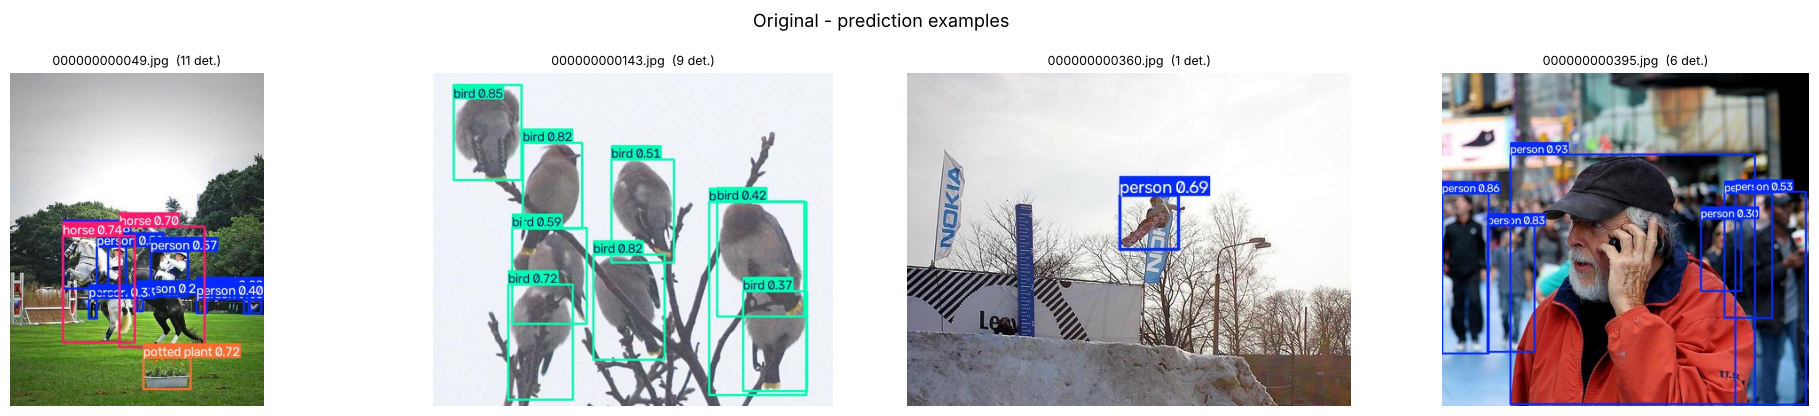

In [4]:
# STAGE 1 — BASELINE ON ORIGINAL IMAGES
import yaml, json, random
import cv2, shutil
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

IMG_DIR = dataset_dir / "images" / "train2017"
LBL_DIR = dataset_dir / "labels" / "train2017"
print("Original images:", len(list(IMG_DIR.glob("*.jpg"))), "| label files:", len(list(LBL_DIR.glob("*.txt"))))

RESULTS = {}          # stage -> four metrics
DET_COUNTS = {}       # stage -> number of detections on the example images

# identical validation settings are used for all three stages
VAL_KW = dict(imgsz=640, batch=16, conf=0.001, iou=0.6, device=DEVICE,
              workers=0, plots=False, verbose=False)

# the same 4 randomly chosen (fixed seed) images are used as prediction examples in every stage
rng = random.Random(42)
EXAMPLES = sorted(rng.sample([p.name for p in sorted(IMG_DIR.glob("*.jpg"))], 4))
print("Example images:", EXAMPLES)


def make_yaml(root, name):
    """Dataset YAML (COCO128 has a single split, so train == val, as in the standard coco128.yaml)."""
    cfg = {"path": str(root), "train": "images/train2017", "val": "images/train2017",
           "names": dict(model.names)}
    p = PROJECT_ROOT / f"{name}.yaml"
    with open(p, "w") as f:
        yaml.safe_dump(cfg, f)
    return p


def evaluate(yaml_path, stage):
    m = model.val(data=str(yaml_path), project=str(PROJECT_ROOT / "val_runs"),
                  name=stage, exist_ok=True, **VAL_KW)
    res = {"Precision": float(m.box.mp), "Recall": float(m.box.mr),
           "mAP@0.5": float(m.box.map50), "mAP@0.5:0.95": float(m.box.map)}
    RESULTS[stage] = res
    print(f"[{stage}]")
    for k, v in res.items():
        print(f"  {k:13s}: {v:.4f}")
    return res


def save_predictions(img_dir, stage):
    """Run model.predict on the example images and save annotated outputs."""
    srcs = [str(img_dir / f) for f in EXAMPLES]
    out = model.predict(srcs, conf=0.25, imgsz=640, device=DEVICE, save=True,
                        project=str(PROJECT_ROOT / "predictions"), name=stage,
                        exist_ok=True, verbose=False)
    DET_COUNTS[stage] = {f: len(r.boxes) for f, r in zip(EXAMPLES, out)}
    folder = PROJECT_ROOT / "predictions" / stage
    print("Saved prediction examples to:", folder)
    print("Detections per example (conf>=0.25):", DET_COUNTS[stage])
    return folder


def show_predictions(folder, title):
    fig, axes = plt.subplots(1, len(EXAMPLES), figsize=(5 * len(EXAMPLES), 4.2))
    for ax, f in zip(axes, EXAMPLES):
        ax.imshow(mpimg.imread(folder / f))
        ax.set_title(f"{f}  ({DET_COUNTS[title][f]} det.)", fontsize=9)
        ax.axis("off")
    fig.suptitle(f"{title} - prediction examples", fontsize=13)
    plt.tight_layout()
    plt.show()


# 1. dataset YAML for the original data
orig_yaml = make_yaml(dataset_dir, "original")
print(open(orig_yaml).read()[:300], "...")

# 2-3. validate and print the four metrics
evaluate(orig_yaml, "Original")

# 4. prediction examples
pred_orig = save_predictions(IMG_DIR, "Original")
show_predictions(pred_orig, "Original")



# Stage 2 — Gaussian Blur

Create a blurred copy of **all COCO128 images**.

### Required blur setting
Use a **9 × 9 Gaussian kernel** with standard OpenCV Gaussian blur.

### Your task
1. Read every original image.
2. Apply Gaussian blur.
3. Save the blurred image with the same filename.
4. Keep the same labels.
5. Evaluate the same YOLO11n detector on the blurred dataset.
6. Record the same four metrics.
7. Save at least **3 blurred prediction examples**.

Do not retrain or replace the detector.


Blurred images written: 128
Label files copied: 128
Ultralytics 8.4.184 🚀 Python-3.13.17 torch-2.14.1+cu130 CPU (Intel Xeon Processor @ 2.80GHz)


YOLO11n summary (fused): 100 layers, 2,616,248 parameters, 0 gradients, 6.5 GFLOPs


val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2941.4±761.6 MB/s, size: 66.9 KB)


val: Scanning /root/fvl_project/blurred/labels/train2017... 126 images, 2 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 128/128 2.6Kit/s 0.1s

val: New cache created: /root/fvl_project/blurred/labels/train2017.cache


...

                   all        128        929      0.701      0.534      0.624       0.44


Speed: 3.6ms preprocess, 93.5ms inference, 0.0ms loss, 2.1ms postprocess per image


[Gaussian Blur]
  Precision    : 0.7012
  Recall       : 0.5337
  mAP@0.5      : 0.6235
  mAP@0.5:0.95 : 0.4401


Results saved to /root/fvl_project/predictions/Gaussian Blur


Saved prediction examples to: /root/fvl_project/predictions/Gaussian Blur
Detections per example (conf>=0.25): {'000000000049.jpg': 4, '000000000143.jpg': 9, '000000000360.jpg': 1, '000000000395.jpg': 8}


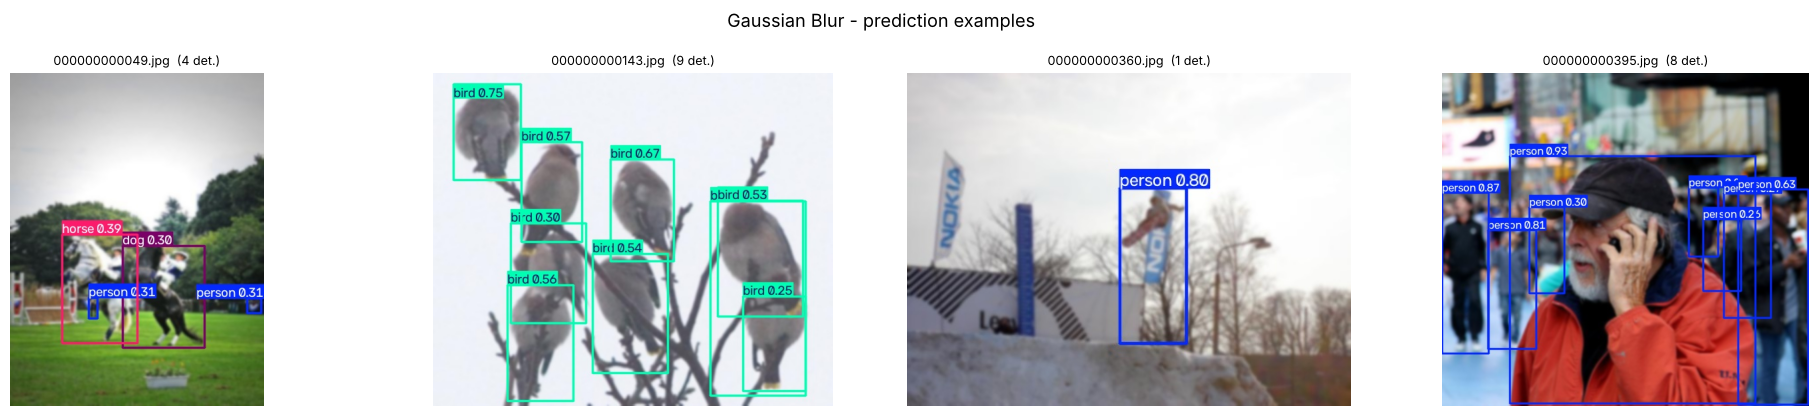

In [5]:
# STAGE 2 — GAUSSIAN BLUR (9 x 9)

import cv2
import shutil

BLURRED_ROOT = PROJECT_ROOT / 'blurred'

# 1. fresh images/ and labels/ folders
if BLURRED_ROOT.exists():
    shutil.rmtree(BLURRED_ROOT)
(BLURRED_ROOT / "images" / "train2017").mkdir(parents=True)

# 2. blur every image, same filename
n = 0
for p in sorted(IMG_DIR.glob("*.jpg")):
    img = cv2.imread(str(p))
    blurred = cv2.GaussianBlur(img, (9, 9), 0)
    cv2.imwrite(str(BLURRED_ROOT / "images" / "train2017" / p.name), blurred)
    n += 1
print("Blurred images written:", n)

# 3. copy the matching labels unchanged
shutil.copytree(LBL_DIR, BLURRED_ROOT / "labels" / "train2017")
print("Label files copied:", len(list((BLURRED_ROOT / "labels" / "train2017").glob("*.txt"))))

# 4. dataset YAML
blur_yaml = make_yaml(BLURRED_ROOT, "blurred")

# 5-6. validate with the same detector and settings, print the four metrics
evaluate(blur_yaml, "Gaussian Blur")

# 7. prediction examples
pred_blur = save_predictions(BLURRED_ROOT / "images" / "train2017", "Gaussian Blur")
show_predictions(pred_blur, "Gaussian Blur")



# Stage 3 — Sharpen the Blurred Images

Apply **one sharpening method** to the Stage 2 blurred images.

You may use a standard sharpening kernel or unsharp masking. Keep the image size unchanged.

### Your task
1. Implement the sharpening operation yourself.
2. Apply it to every blurred image.
3. Save the sharpened images with the same filenames.
4. Keep the same labels.
5. Evaluate the same YOLO11n detector again.
6. Record the same four metrics.
7. Save at least **3 sharpened prediction examples**.

Do not retrain or replace YOLO11n.


Sharpened images written: 128  (unsharp mask, sigma=1.5, amount=1.5)
Ultralytics 8.4.184 🚀 Python-3.13.17 torch-2.14.1+cu130 CPU (Intel Xeon Processor @ 2.80GHz)


YOLO11n summary (fused): 100 layers, 2,616,248 parameters, 0 gradients, 6.5 GFLOPs


val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2420.7±571.3 MB/s, size: 52.3 KB)


val: Scanning /root/fvl_project/sharpened/labels/train2017... 126 images, 2 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 128/128 2.8Kit/s 0.0s

val: New cache created: /root/fvl_project/sharpened/labels/train2017.cache


...

                   all        128        929      0.657      0.556      0.637      0.461


Speed: 3.5ms preprocess, 96.8ms inference, 0.0ms loss, 1.9ms postprocess per image


[Sharpened]
  Precision    : 0.6574
  Recall       : 0.5556
  mAP@0.5      : 0.6375
  mAP@0.5:0.95 : 0.4606


Results saved to /root/fvl_project/predictions/Sharpened


Saved prediction examples to: /root/fvl_project/predictions/Sharpened
Detections per example (conf>=0.25): {'000000000049.jpg': 8, '000000000143.jpg': 8, '000000000360.jpg': 1, '000000000395.jpg': 7}


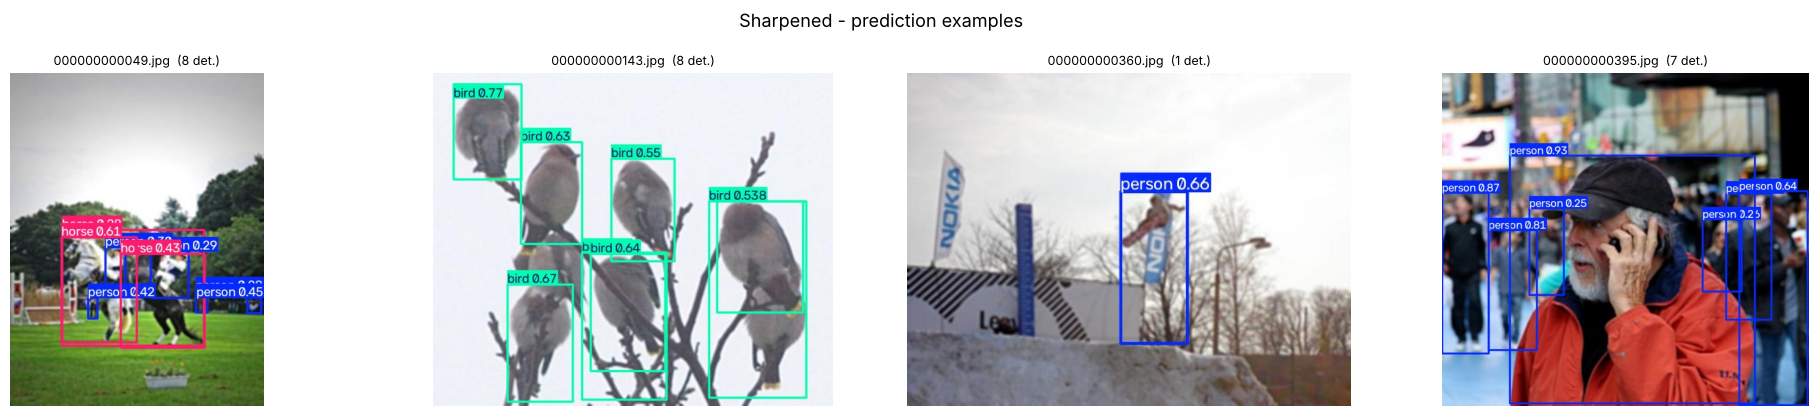

In [6]:
# STAGE 3 — SHARPEN THE BLURRED IMAGES (unsharp masking)

import numpy as np

SHARPENED_ROOT = PROJECT_ROOT / 'sharpened'

# 1. Unsharp masking implemented by hand:
#       sharpened = image + amount * (image - GaussianBlur(image, sigma))
#                 = (1 + amount) * image - amount * blurred_copy
#    The image size is unchanged; values are clipped to [0, 255] by cv2.addWeighted.
SIGMA, AMOUNT = 1.5, 1.5

def unsharp_mask(img, sigma=SIGMA, amount=AMOUNT):
    smooth = cv2.GaussianBlur(img, (0, 0), sigma)          # low-pass copy
    return cv2.addWeighted(img, 1.0 + amount, smooth, -amount, 0)

if SHARPENED_ROOT.exists():
    shutil.rmtree(SHARPENED_ROOT)
(SHARPENED_ROOT / "images" / "train2017").mkdir(parents=True)

# 2. apply to every blurred image (Stage 2 output), same filenames
n = 0
for p in sorted((BLURRED_ROOT / "images" / "train2017").glob("*.jpg")):
    img = cv2.imread(str(p))
    out = unsharp_mask(img)
    assert out.shape == img.shape
    cv2.imwrite(str(SHARPENED_ROOT / "images" / "train2017" / p.name), out)
    n += 1
print(f"Sharpened images written: {n}  (unsharp mask, sigma={SIGMA}, amount={AMOUNT})")

# 3. copy the matching labels
shutil.copytree(LBL_DIR, SHARPENED_ROOT / "labels" / "train2017")

# 4. dataset YAML
sharp_yaml = make_yaml(SHARPENED_ROOT, "sharpened")

# 5-6. validate with the same detector and settings, print the four metrics
evaluate(sharp_yaml, "Sharpened")

# 7. prediction examples
pred_sharp = save_predictions(SHARPENED_ROOT / "images" / "train2017", "Sharpened")
show_predictions(pred_sharp, "Sharpened")


,Precision,Recall,mAP@0.5,mAP@0.5:0.95
Stage,,,,
Original,0.6964,0.5864,0.6771,0.5006
Gaussian Blur,0.7012,0.5337,0.6235,0.4401
Sharpened,0.6574,0.5556,0.6375,0.4606


,Blur vs Original,Sharpened vs Blur,Sharpened vs Original
Precision,+0.0048,-0.0438,-0.0390
Recall,-0.0526,+0.0218,-0.0308
mAP@0.5,-0.0536,+0.0140,-0.0396
mAP@0.5:0.95,-0.0604,+0.0204,-0.0400


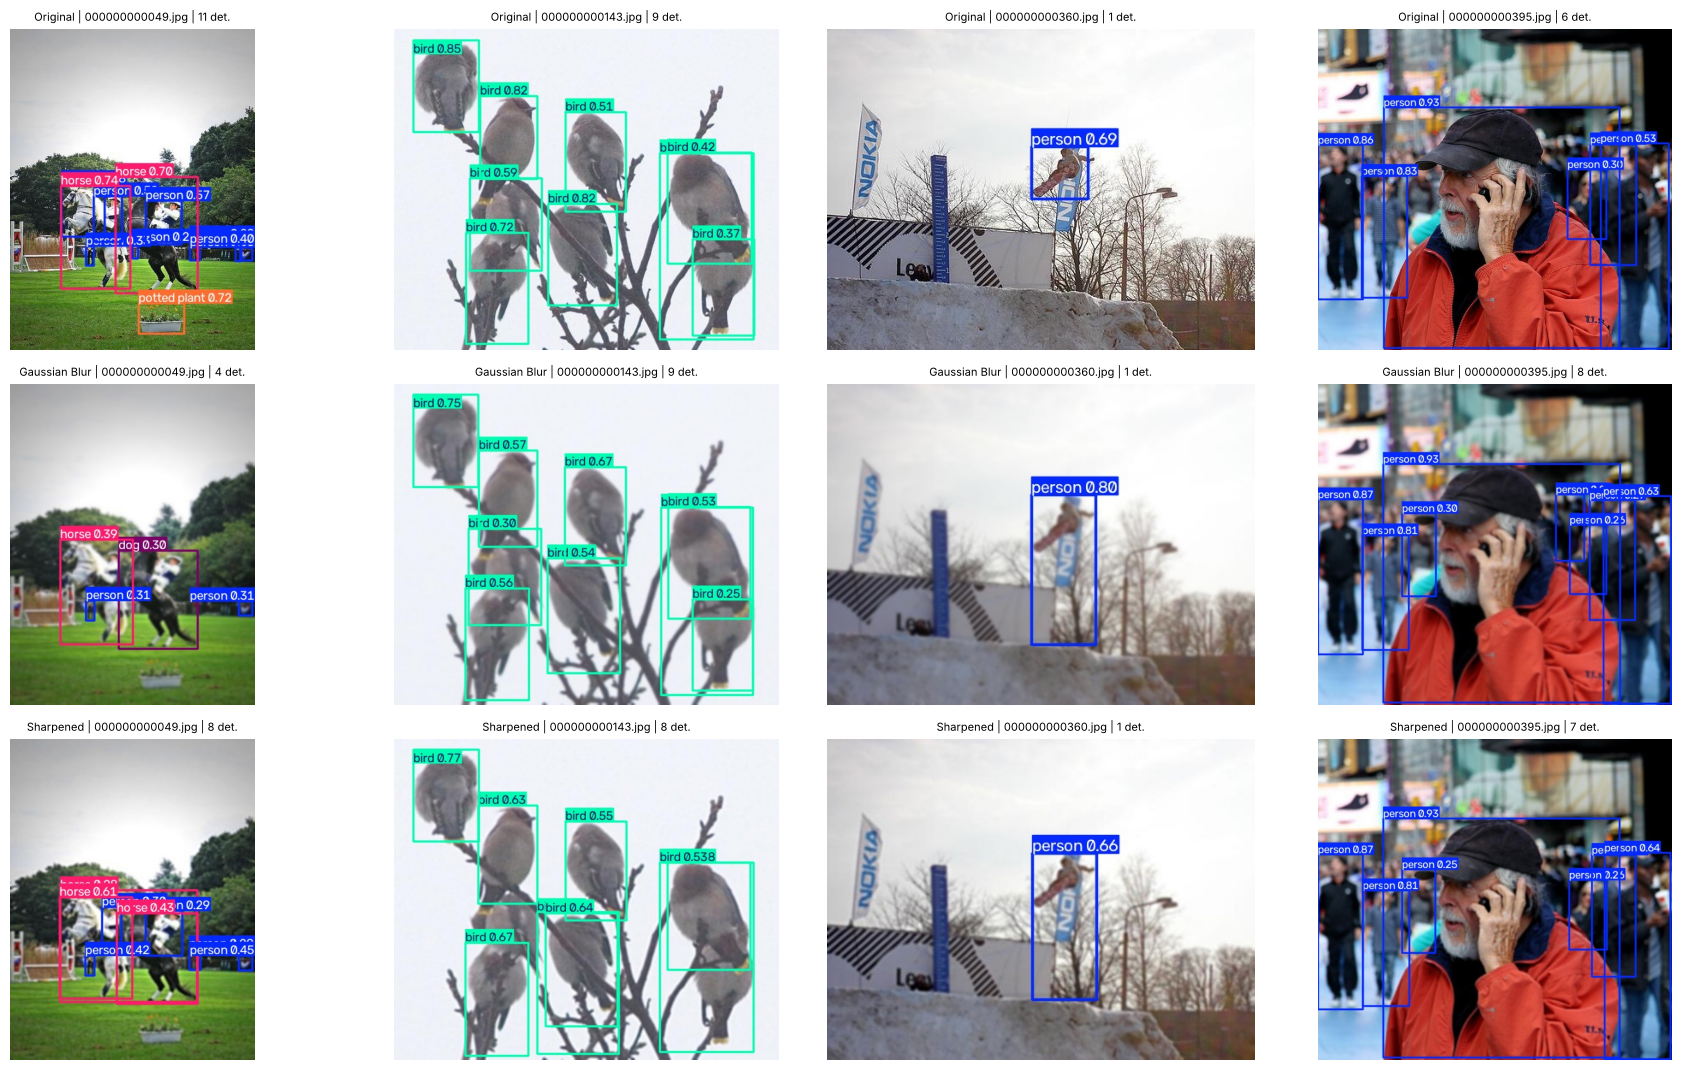

Detections on example images:


,000000000049.jpg,000000000143.jpg,000000000360.jpg,000000000395.jpg
Original,11,9,1,6
Gaussian Blur,4,9,1,8
Sharpened,8,8,1,7


In [7]:
# STAGE 4 — SUMMARY TABLE AND SIDE-BY-SIDE COMPARISON
import pandas as pd
from IPython.display import display

df = pd.DataFrame(RESULTS).T[["Precision", "Recall", "mAP@0.5", "mAP@0.5:0.95"]]
df.index.name = "Stage"
display(df.round(4).style.format("{:.4f}"))

# change relative to the previous stage
delta = pd.DataFrame({"Blur vs Original": df.loc["Gaussian Blur"] - df.loc["Original"],
                      "Sharpened vs Blur": df.loc["Sharpened"] - df.loc["Gaussian Blur"],
                      "Sharpened vs Original": df.loc["Sharpened"] - df.loc["Original"]})
display(delta.round(4).style.format("{:+.4f}"))

with open(PROJECT_ROOT / "results.json", "w") as f:
    json.dump({"metrics": RESULTS, "detections": DET_COUNTS, "examples": EXAMPLES}, f, indent=2)

# grid: rows = stages, columns = example images
stages = ["Original", "Gaussian Blur", "Sharpened"]
fig, axes = plt.subplots(len(stages), len(EXAMPLES), figsize=(4.6 * len(EXAMPLES), 3.6 * len(stages)))
for i, s in enumerate(stages):
    for j, f in enumerate(EXAMPLES):
        ax = axes[i, j]
        ax.imshow(mpimg.imread(PROJECT_ROOT / "predictions" / s / f))
        ax.set_title(f"{s} | {f} | {DET_COUNTS[s][f]} det.", fontsize=8)
        ax.axis("off")
plt.tight_layout()
plt.show()

print("Detections on example images:")
display(pd.DataFrame(DET_COUNTS).T)


# Stage 4 — Final Results - 10 Marks (Code, Results, Prediction Examples)

Enter your final values in the table below and the **values must be upto 4 decimal points.**

| Stage | Precision | Recall | mAP@0.5 | mAP@0.5:0.95 |
|---|---:|---:|---:|---:|
| Original / Baseline | 0.6964 | 0.5864 | 0.6771 | 0.5006 |
| Gaussian Blur | 0.7012 | 0.5337 | 0.6235 | 0.4401 |
| Sharpened | 0.6574 | 0.5556 | 0.6375 | 0.4606 |

*(Same YOLO11n weights and identical `model.val` settings — imgsz 640, conf 0.001, IoU 0.6 — for all three stages; 128 images, 929 instances. Prediction examples use conf ≥ 0.25 on 4 fixed, randomly chosen images.)*

## Analysis — 10 Marks (in points, Max 4 points for each)

### A. Effect of blur — 3 marks
- **Recall dropped the most:** 0.5864 → 0.5337 (−0.0526), i.e. the detector misses more objects once fine detail is smoothed away.
- **Both mAP scores fell:** mAP@0.5 0.6771 → 0.6235 (−0.0536) and mAP@0.5:0.95 0.5006 → 0.4401 (−0.0604). The larger drop in the strict mAP@0.5:0.95 shows that blur hurts box *localisation* (soft edges) even more than plain detection.
- **Precision did not fall** (0.6964 → 0.7012, +0.0048). The model simply makes fewer confident detections, so what it still reports is about as accurate; the loss shows up as missed objects, not as extra false alarms.
- **Prediction examples:** on `000000000049.jpg` detections fell from 11 to 4: the potted plant (0.72) disappeared, the horse confidence dropped 0.74 → 0.39 and one horse was mislabelled as a dog (0.30). On `000000000143.jpg` the birds are still found but with lower confidence (top-left bird 0.85 → 0.75, another 0.59 → 0.30). Large, high-contrast objects survive (`000000000360.jpg`: person 0.69 → 0.80, still 1 detection), so blur mainly harms small, textured, low-contrast objects.

### B. Why sharpening? — 2 marks
I used **unsharp masking**, implemented by hand: `sharpened = (1 + a)·image − a·GaussianBlur(image, σ)` with σ = 1.5 and a = 1.5 (cv2.addWeighted, size unchanged, values clipped to 0–255). Subtracting a low-pass copy isolates the high-frequency detail (edges and texture) and adds it back with a gain, which boosts edge contrast that the 9×9 Gaussian blur attenuated. YOLO relies on edges and local texture for features and for tight box boundaries, so restoring edge contrast can bring the input closer to what the detector saw during training. It cannot recreate information the blur actually destroyed.

### C. Did sharpening help? — 4 marks
Stage 2 → Stage 3 changes:
- **Improved:** Recall 0.5337 → 0.5556 (+0.0218), mAP@0.5 0.6235 → 0.6375 (+0.0140), mAP@0.5:0.95 0.4401 → 0.4606 (+0.0204). The gain is larger in the strict mAP@0.5:0.95, consistent with crisper edges giving better box fit.
- **Got worse:** Precision 0.7012 → 0.6574 (−0.0438). Sharpening amplifies noise, JPEG artefacts and halo/ringing around edges, which creates extra low-confidence or spurious detections (see the duplicated/overlapping boxes in the sharpened row).
- **Not fully recovered:** every metric except precision is still below the original baseline (mAP@0.5 −0.0396, mAP@0.5:0.95 −0.0400, recall −0.0308 vs Original), and precision ends up *below* the baseline as well (−0.0390). Sharpening recovers only roughly a third of the mAP lost to blur.
- **Examples:** on `000000000049.jpg` detections rose from 4 to 8 and the horse confidence from 0.39 to 0.61, but the potted plant was never recovered; on `000000000143.jpg` the top-left bird went 0.75 → 0.77 while detections fell 9 → 8; on `000000000360.jpg` the count stayed 1 and the person confidence fell 0.80 → 0.66; on `000000000395.jpg` detections went 8 → 7 (closer to the 6 of the original, i.e. fewer spurious boxes).
- *Caveats:* a single run on 128 images (COCO128 has only the train split, used here as val), sharpening parameters were not tuned, and images were re-encoded as JPEG at each stage, so small differences should be read cautiously.

### D. Final conclusion — 1 mark
Yes, conditionally. Unsharp masking raised recall (+0.0218), mAP@0.5 (+0.0140) and mAP@0.5:0.95 (+0.0204) over the blurred input and recovered several lost detections, but precision fell by 0.0438 and nothing returned to baseline. Since mAP is the main detection metric, I would keep it as a cheap partial restoration when inputs are known to be blurred, retune the amount to limit false positives, and skip it on sharp images.



# Submission

Submit:
1. Completed `.ipynb` with final results table and with at least 3 prediction examples from each stage: Original, Blurred, Sharpened
2. Google Form for Results, Prediction examples and Analysis submission

Use your roll number in every submitted filename.
Students are requested to submit in time 1 marks will be deducted per day for late submission

Deadline: Sun, 25 October 2026, 11:59 P.M.
